# **Time Series Analysis**
## **Classifying Cardiac Arrhythmias: A Comparative Analysis**

**Authors:** Carla Bellido García, Cindy Chen, Celica Krigul, Keith Megara Osores Vicuña, Ema Štangová
  
**Master:** Health Data Science

**Subject:** Machine Learning

**Course:** 2025-2026

---

## **Table of Contents**

**1. [Overview](#section1)**   

**2. [Dataset](#section2)**  
&emsp; **2.1 [MIT-BIH Arrhythmia Database (PhysioNet)](#section21)**     
&emsp; **2.2 [Classification Target: AAMI 3-Class Scheme](#section22)**  
&emsp; **2.3 [R-Peak Locations](#section22)**  
&emsp; **2.4 [Feature Extraction](#section22)**     
  
**3. [Assignment Tasks](#section3)**  
&emsp; **3.1 [Task 1 - Data Loading & Exploration](#section31)**   
&emsp; **3.2 [Task 2 - Preprocessing & Feature Engineering](#section32)**  
&emsp; **3.3 [Task 3 - RNN: Sequence Classification](#section33)**  
&emsp; **3.4 [Task 4 - Model Comparison & Evaluation](#section34)**  

---
<a id='section1'></a>
## **Overview**

In this assignment you will train, tune, and compare two temporal modelling approaches — Recurrent Neural Networks (RNN) and Long Short-Term Memory networks (LSTM) — on one of the most widely studied biomedical time series benchmarks: the MIT-BIH Arrhythmia Database. Your primary goal is to classify individual heartbeats into one of three clinically meaningful categories, then critically evaluate each method’s strengths and limitations.

The assignment is structured around a single shared feature matrix: you will engineer 8 features per heartbeat that capture rhythm, morphology, and repolarisation. These same features feed every model, making the comparison between methods direct and interpretable. HMM, RNN, and LSTM consume the features differently — independently per beat, or across a sliding window of T = 10 consecutive beats — and understanding why this matters is a central learning objective.

Classification tasks account for approximately 65% of the total marks. This assignment is not a deep learning course: the RNN and LSTM are treated as sequence classifiers, and interpretability of results is expected alongside performance numbers.

---
<a id='section2'></a>
## **Dataset**

<a id='section21'></a>
### **MIT-BIH Arrhythmia Database (PhysioNet)**

The MIT-BIH Arrhythmia Database contains 48 half-hour excerpts of two-channel ambulatory ECG recordings from 47 subjects, digitised at 360 Hz with 11-bit resolution. Each beat has been manually annotated by cardiologists with a symbol indicating its type. The database is freely accessible via the ``wfdb`` Python library, which downloads records directly from PhysioNet — no manual download required.  

```
pip install wfdb
import wfdb
record = wfdb.rdrecord('100', pn_dir='mitdb') # downloads automatically
ann = wfdb.rdann('100', 'atr', pn_dir='mitdb')
signal = record.p_signal[:, 0] # use channel 0 (MLII lead)
```

You will work with the following 14 records, which provide a representative mix of normal rhythm and clinically significant arrhythmias:

```
100, 101, 105, 106, 108, 109, 111, 112, 115, 117, 119, 201, 213, 219
``` 

This subset yields approximately 35,000–40,000 labelled beats, sufficient for robust model training and evaluation. 

<a id='section22'></a>
### **Classification Target: AAMI 3-Class Scheme**

The raw annotation files contain over 15 distinct beat symbols. You will map these to a simplified 3-class scheme based on the AAMI EC57 standard, which is the convention used in most published benchmark results on this dataset:

```
label_map = {
 # N — Normal
 'N': 'N', '.': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
 # S — Supraventricular ectopic
 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
 # V — Ventricular ectopic
 'V': 'V', 'E': 'V',
 # All other symbols: discard
}
```  

Any beat whose symbol does not appear in label_map (e.g. pacemaker beats ‘P’, noise ‘~’, rhythm annotations) should be discarded. Document how many beats you discard and from which classes.

| **Class** | **Label** | **Typical examples** | **Expected frequency** |
|---|---|---|---|
| N | Normal / bundle branch beats | Normal sinus, LBBB, RBBB, escape beats | ∼ 80–90% of all beats |
| S | Supraventricular ectopic | Atrial premature (A), nodal (J) | ∼ 2–5% |
| V | Ventricular ectopic | PVC (V), ventricular escape (E) | ∼ 5–10% |  

Note the strong class imbalance: N beats dominate the dataset. You are expected to discuss how this affects your models and evaluation choices (e.g. why macro F1 is more informative than accuracy here).

<a id='section23'></a>
### **R-Peak Locations**

R-peak locations are provided directly in the annotation files and do not need to be detected algorithmically. The annotation object returned by ``wfdb`` gives you:

```
ann.sample # numpy array of R-peak sample indices (one per beat)
ann.symbol # numpy array of beat label strings, same length as
ann.sample
```

You should use ann.sample as the authoritative R-peak positions for all feature extraction. Do not apply an independent peak detector.

<a id='section24'></a>
### **Feature Extraction**

You will engineer **8 features per beat**. These same features are used by **all three models**. HMM receives one feature vector per beat; RNN and LSTM receive a sliding window of T = 10 consecutive beat vectors (shape: 10 × 8) with the label taken from the final beat in the window.

| **#** | **Feature** | **Extraction Window** | **Clinical Meaning** |
|---|---|---|---|
| 1 | RR_current | Beat i | Current RR interval (ms) — primary rate indicator |
| 2 | RR_prev | Beat i−1 | Previous RR interval — captures beat-to-beat variability |
| 3 | RR_ratio | Beat i | RR_current / RR_local_mean — relative rate change |
| 4 | RR_local_mean | Beats i−4 to i | 5-beat rolling mean RR — local rhythm baseline |
| 5 | R_amplitude | ±5 samples | Signal amplitude at the R-peak |
| 6 | QRS_duration | Threshold crossing | Width of QRS above 50% of R amplitude |
| 7 | QRS_energy | ±20 samples | Sum of squared signal values around R-peak |
| 8 | ST_mean | +40 to +120 samples | Mean signal in ST segment — repolarisation indicator |

---
<a id='section3'></a>
## **Assignment Tasks**

The assignment follows a single end-to-end pipeline. All team members should understand every stage, even if responsibilities are divided.

In [1]:
# !pip install wfdb

In [2]:
# !pip install torch

In [3]:
# Libraries used
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import time
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
)
from collections import Counter

import wfdb

In [4]:
# For Reproducibility:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Plot style
ACCENT1 = "#58a6ff"  # blue
ACCENT2 = "#3fb950"  # green
ACCENT3 = "#f85149"  # red
ACCENT4 = "#d2a8ff"  # purple

<a id='section31'></a>
### **Task 1 - Data Loading & Exploration**

- **Load all 14 records using ``wfdb``. For at least two records, plot a 5-second segment of the raw ECG signal with R-peak positions marked. Annotate visible beat types.**

In [5]:
# List of the 14 records
all_records = [
    "100",
    "101",
    "105",
    "106",
    "108",
    "109",
    "111",
    "112",
    "115",
    "117",
    "119",
    "201",
    "213",
    "219",
]

In [6]:
# Load dataset
records = {}
anns = {}
signals = {}
r_peaks = {}
symbols = {}

records_data = []

for rid in all_records:
    rec = wfdb.rdrecord(rid, pn_dir="mitdb")  # downloads automatically
    ann = wfdb.rdann(rid, "atr", pn_dir="mitdb")

    records[rid] = rec
    anns[rid] = ann
    signals[rid] = rec.p_signal[:, 0]  # use channel 0 (MLII lead)
    r_peaks[rid] = ann.sample
    symbols[rid] = ann.symbol

    records_data.append((rid, rec, ann))

In [7]:
# Sampling frequency
fs = 360


def plot_ecg_segment(sample):
    """
    Plot a raw ECG segment with R-peak markers and beat-type annotations.
    """
    # 5s * 360 Hz = 1800 points
    segment_len = 5 * fs
    signal_segment = signals[sample][:segment_len]

    # keep only the ones inside the 5s
    peaks_segment = [p for p in r_peaks[sample] if p < segment_len]
    symbols_segment = symbols[sample][: len(peaks_segment)]

    # plotting
    plt.figure(figsize=(12, 5))
    plt.plot(signal_segment, color="black", label="ECG")
    plt.scatter(
        peaks_segment, signal_segment[peaks_segment], color="red", label="R-peak"
    )

    for idx, sym in zip(peaks_segment, symbols_segment):
        y_koordinaat = signal_segment[idx]
        plt.text(idx, y_koordinaat + 0.15, sym, color="blue", fontsize=12, ha="center")

    plt.title(f"Record {sample}")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude (mV)")
    plt.xlim(0, segment_len)
    plt.ylim(-1, 2)
    plt.grid(True, linestyle="--")
    plt.legend()
    plt.savefig(f"figures/Task1_ECG_segment_{sample}.png", dpi=150)
    plt.show()

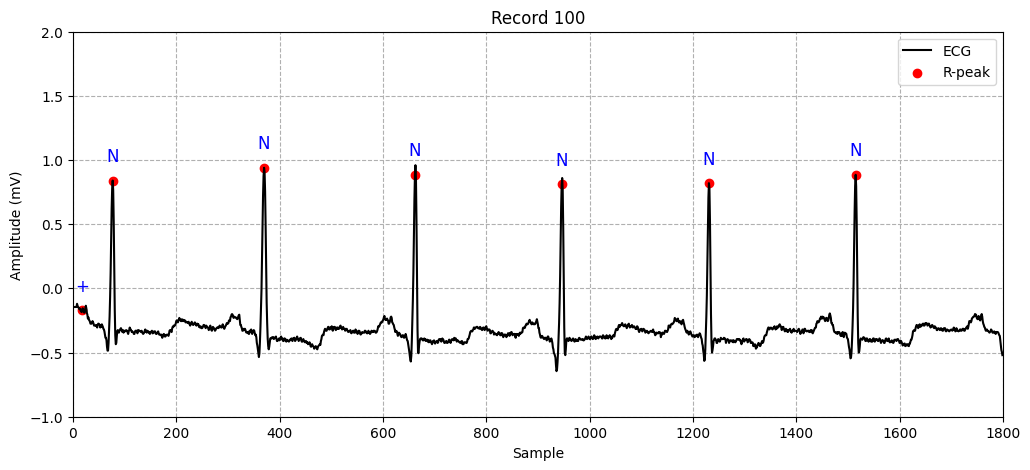

In [8]:
# Plot 5-second segment of record 100
plot_ecg_segment("100")

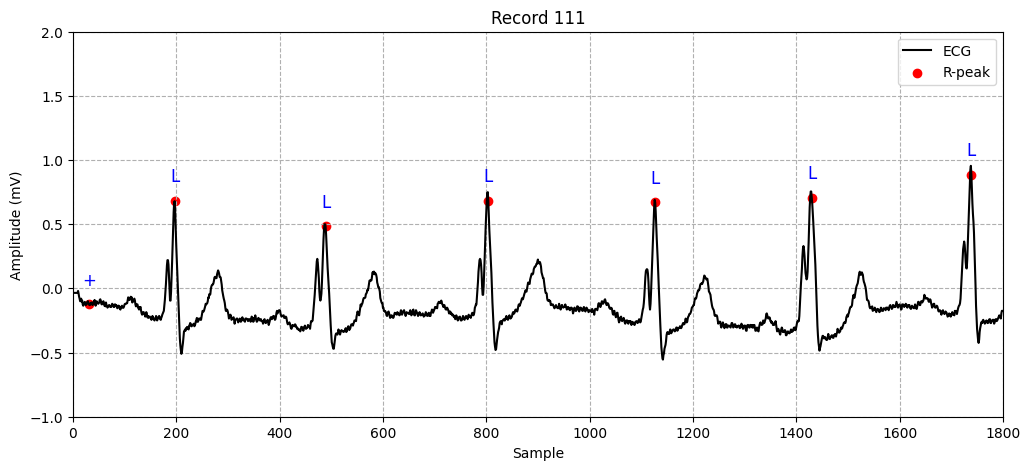

In [9]:
# Plot 5-second segment of record 111
plot_ecg_segment("111")

- **Report the total number of beats per class (N, S, V) across all 14 records. Produce a bar chart of the class distribution. Is the dataset imbalanced? Discuss how imbalance might affect model training and which evaluation metrics are most appropriate.**

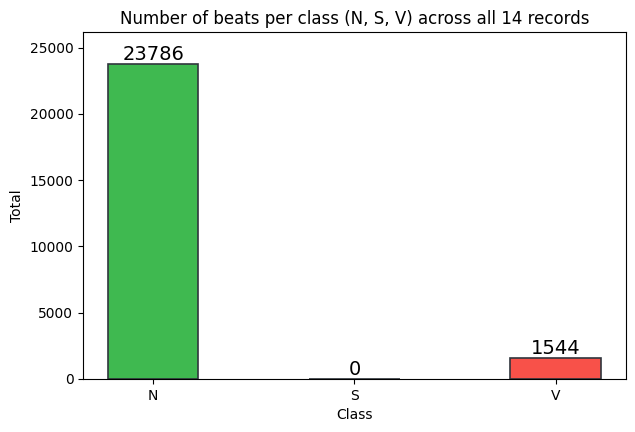

In [10]:
colors = [ACCENT2, ACCENT4, ACCENT3]
class_counts = {"N": 0, "S": 0, "V": 0}

# looping through all symbols matching N, S, V in all records and adding +1 to the counter if encountered
for record in all_records:
    for sym in symbols[record]:
        if sym in class_counts:
            class_counts[sym] += 1

# Class distribution bar chart before mapping
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    class_counts.keys(),
    class_counts.values(),
    color=colors,
    width=0.45,
    edgecolor="#30363d",
    linewidth=1.2,
)
ax.set_title("Number of beats per class (N, S, V) across all 14 records")
ax.set_xlabel("Class")
ax.set_ylabel("Total")
ax.bar_label(bars, fontsize=14)
ax.set_ylim(0, max(class_counts.values()) * 1.1)
plt.savefig("figures/Task1_Original_Class_distribution.png", dpi=150)
plt.show()

Following the assignment, we have plotted only the number of beats in classes N, S, V before mapping other beat symbols according to the standard. Therefore, this graph does not give us a complete picture of what will later be the training and test data. However, we can say that an imbalanced dataset affects model training and stratification should be used to preserve the ratios of classes in train and test data. Furthermore, accuracy would not be the most appropriate metric, and rather we would use f1_macro giving us the harmonic mean between precision and recall, separated by classes.

- **After computing the 8 features in Task 2, produce a correlation heatmap of the feature matrix. Identify and briefly discuss the most strongly correlated pairs.**

    _See this part inside Task 2_

<a id='section32'></a>
### **Task 2 - Preprocessing & Feature Engineering**

In [11]:
LABEL_MAP = {
    # N — Normal
    "N": "N",
    ".": "N",
    "L": "N",
    "R": "N",
    "e": "N",
    "j": "N",
    # S — Supraventricular ectopic
    "A": "S",
    "a": "S",
    "J": "S",
    "S": "S",
    # V — Ventricular ectopic
    "V": "V",
    "E": "V",
}

FEATURE_NAMES = [
    "RR_current",
    "RR_prev",
    "RR_ratio",
    "RR_local_mean",
    "R_amplitude",
    "QRS_duration",
    "QRS_energy",
    "ST_mean",
]

WINDOW_SIZE = 10  # sliding window for RNN / LSTM

- **Load annotations for all 14 records. Apply label_map to map raw symbols to N, S, or V. Discard beats with unmapped symbols and report the count discarded.**

Prior to mapping, we obtained 23786 normal beats ("N"), 0 supraventricular ectopic beats ("S") and 1544 Ventricular ectopic beats ("V"). However, since 3-class scheme mapping based on the AAMI EC57 standard was applied, 28412 normal beats, 206 supraventricular ectopic beats and 1544 ventricular ectopic beats were recognized.

While keeping a total of 30162 beats, the number of discarded beats (i.e. unmapped symbols) was 1057.

Therefore, we observed that the dataset is heavily imbalanced: N beats represent 94.2% of all beats, while S and V are rare, constituing 0.7% and 5.1%, respectively. Consequently, a model that always predicts N beats achieves high accuracy (~90 %) yet misses every arrhythmia. Thus, the appropriate metrics in this case are:

- Macro F1-score: It weights equally all classes regardless of frequency, meaning it punishes poor minority-class recall.
- Cohen's Kappa: It accounts for chance agreement.
- Per-class Precision / Recall / F1 in a full classification report.
- Confusion matrix: It exposes false negatives for S and V which carry clinical risk.

Then, some strategies to mitigate these disadvantages are implementing stratified splits that preserve ratios in train/test, having class-weighted cross-entropy loss and applying SMOTE to oversample minority classes.

- **Extract all 8 features per beat as specified in the Feature Extraction section. Handle the first-beat edge case and document your approach.**

In [12]:
# Feature extraction function
FS = 360


def extract_features(sig: np.ndarray, r_samples: np.ndarray) -> np.ndarray:
    """
    Extract the 8 specified features for every beat.

    Edge-case handling (beat index 0):
      • RR_current  : set to the dataset median RR (computed after a first pass).
      • RR_prev     : set to RR_current (no prior beat available).
      • RR_ratio    : set to 1.0 (neutral — no relative change).
      • RR_local_mean: use available beats i–4..i; for i<4 use beats 0..i.
    All other features are computed directly from the signal window.
    """
    n_beats = len(r_samples)
    X = np.zeros((n_beats, 8), dtype=np.float32)
    samples_to_ms = 1000.0 / FS

    # First pass: compute all RR intervals for median
    rr_all = np.diff(r_samples).astype(float) * samples_to_ms
    rr_median = float(np.median(rr_all)) if len(rr_all) > 0 else float(FS)

    for i, r in enumerate(r_samples):
        # 1. RR_current — beat i interval
        if i == 0:
            rr_cur = rr_median  # edge case
        else:
            rr_cur = float(r_samples[i] - r_samples[i - 1]) * samples_to_ms

        # 2. RR_prev — beat i-1 interval
        if i <= 1:
            rr_prev = rr_cur  # edge case
        else:
            rr_prev = float(r_samples[i - 1] - r_samples[i - 2]) * samples_to_ms

        # 3. RR_local_mean — 5-beat rolling mean (beats i-4 to i)
        lo = max(0, i - 4)
        window_r = r_samples[lo : i + 1]
        if len(window_r) >= 2:
            rr_local_mean = float(np.mean(np.diff(window_r))) * samples_to_ms
        else:
            rr_local_mean = rr_cur

        # 4. RR_ratio
        rr_ratio = rr_cur / rr_local_mean if rr_local_mean > 0 else 1.0

        # 5. R_amplitude — amplitude at annotated R-peak
        r_amplitude = float(sig[r])

        # 6. QRS_duration — approximate threshold-crossing width
        threshold = 0.5 * abs(r_amplitude)

        left = r
        while left > 0 and abs(sig[left]) > threshold:
            left -= 1

        right = r
        while right < len(sig) - 1 and abs(sig[right]) > threshold:
            right += 1

        qrs_duration = float(right - left) * samples_to_ms

        # 7. QRS_energy — sum of squared signal values ±20 samples
        lo20 = max(0, r - 20)
        hi20 = min(len(sig), r + 21)
        qrs_energy = float(np.sum(sig[lo20:hi20] ** 2))

        # 8. ST_mean — mean signal in ST segment (+40 to +120 samples)
        lo_st = min(len(sig), r + 40)
        hi_st = min(len(sig), r + 120)
        st_mean = float(np.mean(sig[lo_st:hi_st])) if lo_st < hi_st else 0.0

        X[i] = [
            rr_cur,
            rr_prev,
            rr_ratio,
            rr_local_mean,
            r_amplitude,
            qrs_duration,
            qrs_energy,
            st_mean,
        ]

    return X

In [13]:
# Feature matrix function
def build_feature_matrix(records_data: list):
    """
    Extract features record-by-record.
    Returns:
        dataset_per_record = list of (X_rec, y_rec)
        discarded count
    """
    dataset_per_record = []
    discarded = 0
    kept_counts = Counter()
    discarded_by_symbol = Counter()

    for rec_id, rec, ann in records_data:
        sig = rec.p_signal[:, 0]

        filtered_samples = []
        filtered_labels = []

        # Map symbols to N, S, V and filter out unmapped beats
        for s, sym in zip(ann.sample, ann.symbol):
            mapped = LABEL_MAP.get(sym, None)

            if mapped is None:
                discarded += 1
                discarded_by_symbol[sym] += 1
                continue

            filtered_samples.append(s)
            filtered_labels.append(mapped)
            kept_counts[mapped] += 1

        filtered_samples = np.array(filtered_samples)

        X_rec = extract_features(sig, filtered_samples)

        dataset_per_record.append((X_rec, np.array(filtered_labels)))

    print(f"Discarded beats (unmapped symbols): {discarded}")
    for sym, cnt in discarded_by_symbol.most_common():
        print(f"  {sym}: {cnt}")
    print(f"\nKept beats: {sum(kept_counts.values()):}")

    for cls in ["N", "S", "V"]:
        print(f"  {cls}: {kept_counts[cls]:}")

    return dataset_per_record

In [14]:
# Feature extraction
dataset_per_record = build_feature_matrix(records_data)

# Concatenate for exploratory analysis
X = np.concatenate([d[0] for d in dataset_per_record], axis=0)
y = np.concatenate([d[1] for d in dataset_per_record], axis=0)

print(f"\nFeature matrix shape: {X.shape}")

Discarded beats (unmapped symbols): 1057
  F: 369
  +: 252
  ~: 196
  x: 181
  |: 48
  Q: 7
  ": 4

Kept beats: 30162
  N: 28412
  S: 206
  V: 1544

Feature matrix shape: (30162, 8)


The first heartbeat in each ECG record presents an edge case because several rhythm-based features depend on previous beats and therefore cannot be computed directly for beat (i = 0). To handle this, a neutral and physiologically reasonable initialization strategy was applied. The `RR_current` value for the first beat was set to the median RR interval of the record, providing a representative estimate of a typical heartbeat interval. Since no preceding beat exists, `RR_prev` was set equal to `RR_current`, while `RR_ratio` was assigned a value of 1.0 to indicate no relative deviation from the local rhythm baseline. For `RR_local_mean`, the rolling mean was computed using all available preceding beats. Therefore, for early beats where fewer than five intervals existed, the mean was calculated from the reduced available window. The remaining morphology-based features (`R_amplitude`, `QRS_duration`, `QRS_energy`, and `ST_mean`) were computed directly from the ECG waveform around the annotated R-peak and did not require special handling. This approach avoids introducing missing values while preserving physiologically plausible feature behaviour at the beginning of each record.

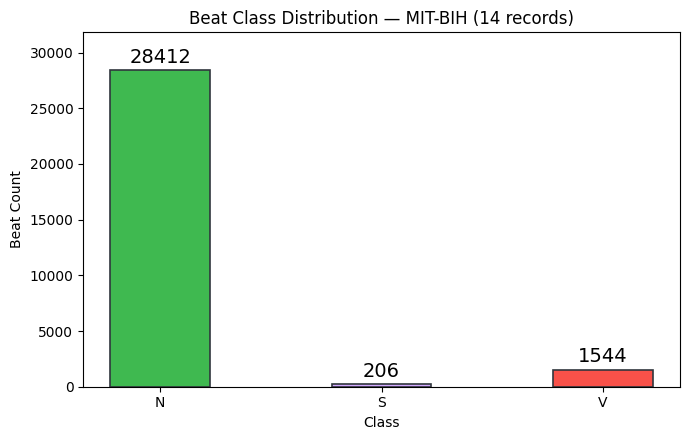


Class Distribution:
  N:  28412  (94.2%)
  S:    206  (0.7%)
  V:   1544  (5.1%)
  Total: 30162


In [15]:
# Class distribution bar chart after mapping function
def plot_class_distribution(class_counts: dict):
    """
    Bar chart of N / S / V beat counts with imbalance discussion.
    """
    classes = ["N", "S", "V"]
    counts = [class_counts.get(c, 0) for c in classes]
    colors = [ACCENT2, ACCENT4, ACCENT3]

    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(
        classes, counts, color=colors, width=0.45, edgecolor="#30363d", linewidth=1.2
    )
    for bar, cnt in zip(bars, counts):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(counts) * 0.01,
            f"{cnt:}",
            ha="center",
            va="bottom",
            fontsize=14,
            color="#000000",
        )

    ax.set_title("Beat Class Distribution — MIT-BIH (14 records)")
    ax.set_xlabel("Class")
    ax.set_ylabel("Beat Count")
    ax.set_ylim(0, max(counts) * 1.12)
    fig.tight_layout()
    plt.savefig("figures/Task2_Mapped_Class_distribution.png", dpi=150)
    plt.show()

    total = sum(counts)
    print("\nClass Distribution:")
    for cls, cnt in zip(classes, counts):
        print(f"  {cls}: {cnt:>6}  ({100 * cnt / total:.1f}%)")
    print(f"  Total: {total:}")


# Class distribution bar chart after mapping
class_counts = Counter(y)
plot_class_distribution(class_counts)

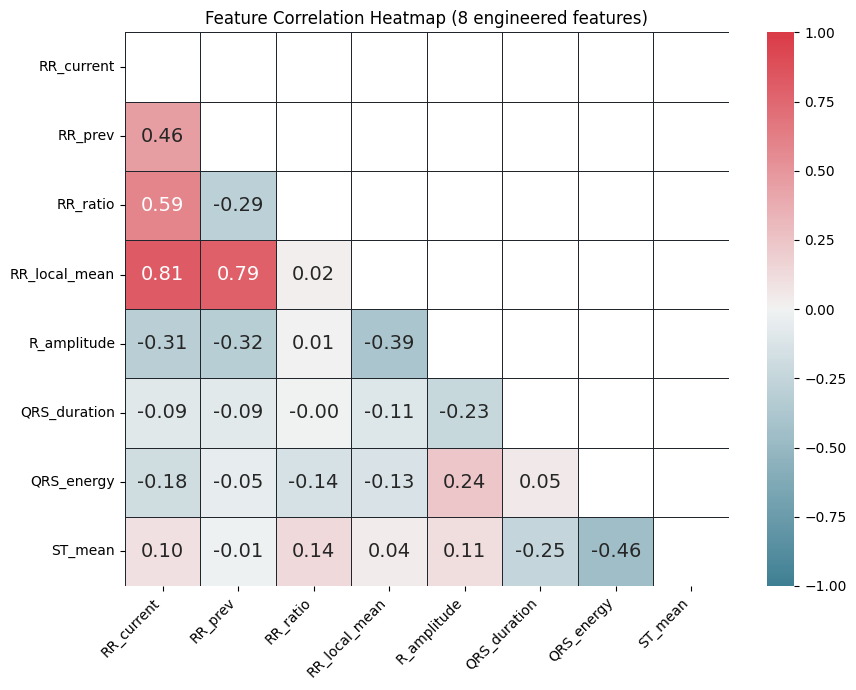


  Top correlated feature pairs:
    RR_local_mean   ↔ RR_current       r = +0.813
    RR_local_mean   ↔ RR_prev          r = +0.791
    RR_ratio        ↔ RR_current       r = +0.588
    RR_prev         ↔ RR_current       r = +0.460
    ST_mean         ↔ QRS_energy       r = -0.459


In [16]:
# Correlation heatmap function
def plot_correlation_heatmap(X: np.ndarray, feature_names: list):
    """Correlation heatmap of the 8-feature matrix."""
    df = pd.DataFrame(X, columns=feature_names)
    corr = df.corr()

    fig, ax = plt.subplots(figsize=(9, 7))
    mask = np.triu(np.ones_like(corr, dtype=bool))
    cmap = sns.diverging_palette(220, 10, as_cmap=True)
    sns.heatmap(
        corr,
        mask=mask,
        cmap=cmap,
        vmax=1,
        vmin=-1,
        center=0,
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        linecolor="#21262d",
        ax=ax,
        annot_kws={"size": 14},
    )
    plt.xticks(rotation=45, ha="right")
    ax.set_title("Feature Correlation Heatmap (8 engineered features)")
    fig.tight_layout()
    plt.savefig("figures/Task1_Correlation_heatmap.png", dpi=150)
    plt.show()

    # Print top correlated pairs
    corr_pairs = (
        corr.where(~mask)
        .stack()
        .reset_index()
        .rename(columns={0: "r", "level_0": "feat_a", "level_1": "feat_b"})
    )
    corr_pairs["abs_r"] = corr_pairs["r"].abs()
    top = corr_pairs.sort_values("abs_r", ascending=False).head(5)
    print("\n  Top correlated feature pairs:")
    for _, row in top.iterrows():
        print(f"    {row.feat_a:15s} ↔ {row.feat_b:15s}  r = {row.r:+.3f}")


# Correlation heatmap
plot_correlation_heatmap(X, FEATURE_NAMES)

As expected, the pair of features that present strong positive correlations are:

- ``RR_current`` and ``RR_local_mean`` (0.813):  local mean is computed FROM RR_current; by construction they co-move.
- ``RR_current`` and ``RR_prev`` (0.46): consecutive intervals are auto-correlated (heart rhythm is relatively stable).

Weaker correlations (desirable independence):

The strongest correlations were primarily observed among the RR-interval–based features, which is expected because they all describe short-term heart rhythm dynamics. In particular, `RR_local_mean` showed strong positive correlations with both `RR_current` (r = +0.813) and `RR_prev` (r = +0.791). This occurs because the local mean is computed directly from recent RR intervals, including the current and previous beats, so these features naturally co-vary. Physiologically, consecutive RR intervals are typically similar during stable sinus rhythm, reflecting the gradual regulation of heart rate by the autonomic nervous system. A moderate positive correlation was also observed between `RR_ratio` and `RR_current` (r = +0.588), since the ratio uses the current RR interval in its numerator. Similarly, `RR_prev` and `RR_current` (r = +0.460) were moderately correlated, demonstrating the temporal continuity of cardiac rhythm while still allowing variability introduced by arrhythmic events.

The strongest negative correlation was found between `ST_mean` and `QRS_energy` (r = -0.459). `QRS_energy` measures the power of ventricular depolarisation around the QRS complex, while `ST_mean` characterises the average amplitude of the ST segment associated with ventricular repolarisation. The negative relationship suggests that beats with large, high-energy QRS complexes may exhibit altered or lower ST-segment amplitudes, which is often seen in abnormal ventricular activity such as ectopic beats. Importantly, this correlation is only moderate, indicating that morphology and repolarisation features provide complementary rather than redundant information.

In addition, weaker correlation was found between ST_mean vs RR features (-0.01-0.14) given that repolarisation and rhythm are physiologically decoupled, lending complementary diagnostic information. Another independent features were RR_ratio vs R amplitude (0.01) since rate change and morphology capture different arrhythmia dimensions.

Overall, the correlation analysis suggests that rhythm-based features are internally related, whereas morphology and repolarisation-based features contribute additional independent information that may improve arrhythmia classification performance.

- **Scaling: apply StandardScaler to the 8 features. Fit on the training set only and transform both train and test sets.**

- **Train/test split: apply a stratified 80/20 random split (random_state=42). Verify that class proportions are preserved in both splits and report the beat counts per class in each set.**

In [17]:
# Train / test split function
def make_splits(X: np.ndarray, y: np.ndarray, label2int: dict):
    """Stratified 80/20 split and report class preservation."""
    y_int = np.array([label2int[lbl] for lbl in y])
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y_int, test_size=0.2, random_state=SEED, stratify=y_int
    )

    print("\nTrain / Test Split (stratified 80 / 20)")
    int2label = {v: k for k, v in label2int.items()}
    for split_name, y_split in [("Train", y_tr), ("Test", y_te)]:
        c = Counter(y_split)
        total = len(y_split)
        print(f"\n  {split_name} ({total:,} beats):")
        for code, lbl in int2label.items():
            cnt = c.get(code, 0)
            print(f"    {lbl}: {cnt:>6,}  ({100 * cnt / total:.1f}%)")

    return X_tr, X_te, y_tr, y_te


# Train / test split
label2int = {"N": 0, "S": 1, "V": 2}
X_tr, X_te, y_tr, y_te = make_splits(X, y, label2int)

# StandardScaler (fit on train only, transform both)
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr).astype(np.float32)
X_te = scaler.transform(X_te).astype(np.float32)


Train / Test Split (stratified 80 / 20)

  Train (24,129 beats):
    N: 22,729  (94.2%)
    S:    165  (0.7%)
    V:  1,235  (5.1%)

  Test (6,033 beats):
    N:  5,683  (94.2%)
    S:     41  (0.7%)
    V:    309  (5.1%)


As can be seen, class proportions are preserved in both splits and report the beat counts per class in each set. The beats counts are shown in the table below:

| Dataset | Total Beats |      N |   N % |   S |  S % |     V |  V % |
| ------- | ----------: | -----: | ----: | --: | ---: | ----: | ---: |
| Train   |      24,129 | 22,729 | 94.2% | 165 | 0.7% | 1,235 | 5.1% |
| Test    |       6,033 |  5,683 | 94.2% |  41 | 0.7% |   309 | 5.1% |


- **Construct the sliding window dataset for RNN and LSTM: for each beat at position i ≥ 10, create a sample consisting of the feature vectors for beats i−9 through i (shape: 10 × 8) with label equal to the class of beat i. Apply the same 80/20 split.**

In [18]:
def make_windows(X: np.ndarray, y: np.ndarray, window: int = WINDOW_SIZE):
    """
    Build sliding window sequences for RNN / LSTM.
    For beat i ≥ window, sample = X[i-window+1 : i+1]  shape (window, 8)
    Label = y[i].
    """
    Xw, yw = [], []
    for i in range(window - 1, len(X)):
        Xw.append(X[i - window + 1 : i + 1])
        yw.append(y[i])
    return np.array(Xw, dtype=np.float32), np.array(yw)


# Sliding window dataset
# Windows are built per record to avoid crossing record boundaries.
# After all windows are created, we apply one global stratified split.

Xw_all = []
yw_all = []

for X_rec, y_rec_str in dataset_per_record:
    # Integer labels
    y_rec = np.array([label2int[v] for v in y_rec_str])

    # Scale using global scaler fit only on training beats
    X_rec_scaled = scaler.transform(X_rec).astype(np.float32)

    # Create windows inside this record only
    Xw_rec, yw_rec = make_windows(X_rec_scaled, y_rec, WINDOW_SIZE)

    if len(Xw_rec) > 0:
        Xw_all.append(Xw_rec)
        yw_all.append(yw_rec)

# Concatenate all record-wise windows
X_w = np.concatenate(Xw_all, axis=0)
y_w = np.concatenate(yw_all, axis=0)

print(f"Sliding window dataset shape: {X_w.shape}")

# Final stratified split on windows
X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(
    X_w, y_w, test_size=0.2, random_state=SEED, stratify=y_w
)

print(f"  Window train: {X_tr_w.shape}")
print(f"  Window test : {X_te_w.shape}")

Sliding window dataset shape: (30036, 10, 8)
  Window train: (24028, 10, 8)
  Window test : (6008, 10, 8)


<a id='section33'></a>
### **Task 3 - RNN: Sequence Classification**

- **Dataset: use the sliding window dataset from Task 2 (shape per sample: 10 × 8). Each sample is a sequence of 10 consecutive beats; the label is the class of the final beat.**

In [19]:
# Testing
print(X_tr_w.shape)  # WINDOW TRAIN
print(X_te_w.shape)  # WINDOW TEST

(24028, 10, 8)
(6008, 10, 8)


The RNN/LSTM models were trained using the sliding window dataset from Task 2. Each input sample is a sequence of 10 consecutive beats with 8 features per beat, while the label corresponds to the class of the last beat in the sequence.

- **Implement a vanilla RNN classifier in PyTorch (torch.nn.RNN) with one hidden layer and a Linear output layer for 3-class classification. Use cross-entropy loss and the Adam optimiser** 

In [20]:
# Vanilla RNN classifier
rnn = nn.RNN(input_size=8, hidden_size=64, num_layers=1, batch_first=True)

# Final classification layer
head = nn.Linear(64, 3)

# Adam optimizer
optimizer = torch.optim.Adam(list(rnn.parameters()) + list(head.parameters()), lr=0.001)

# Multi-class classification loss
criterion = nn.CrossEntropyLoss()

A vanilla RNN was implemented using one recurrent hidden layer ``hidden_size = 64`` and a Linear output layer for 3 class classification. The model was trained using the Adam optimizer and cross-entropy loss

- **Train for at least 20 epochs. Plot training and validation loss and accuracy curves per epoch.**

In [21]:
# Add validation set
X_train, X_val, y_train, y_val = train_test_split(
    X_tr_w,
    y_tr_w,
    test_size=0.2,
    random_state=SEED,
    stratify=y_tr_w,
)

In [22]:
# Create DataLoaders for train, validation, and test sets
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long),
    ),
    batch_size=64,
    shuffle=True,
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.long),
    ),
    batch_size=64,
    shuffle=False,
)

test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_te_w, dtype=torch.float32),
        torch.tensor(y_te_w, dtype=torch.long),
    ),
    batch_size=64,
    shuffle=False,
)

The data were transformed into PyTorch tensors and organized into batches of 64 samples using DataLoader for training, validation, and testing

In [23]:
EPOCHS = 20
train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

# Training loop with validation
for epoch in range(EPOCHS):
    rnn.train()
    head.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    # Iterate over training batches
    for x, y in train_loader:
        optimizer.zero_grad()
        output, _ = rnn(x)
        last_hidden = output[:, -1, :]
        pred = head(last_hidden)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_correct += (pred.argmax(1) == y).sum().item()
        train_total += y.size(0)

    rnn.eval()
    head.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            output, _ = rnn(x)
            last_hidden = output[:, -1, :]
            pred = head(last_hidden)
            loss = criterion(pred, y)
            val_loss += loss.item()
            val_correct += (pred.argmax(1) == y).sum().item()
            val_total += y.size(0)

    train_loss_history.append(train_loss / len(train_loader))
    val_loss_history.append(val_loss / len(val_loader))

    train_acc_history.append(train_correct / train_total)
    val_acc_history.append(val_correct / val_total)

    # Print epoch metrics
    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss: {train_loss_history[-1]:.4f}, "
        f"Val Loss: {val_loss_history[-1]:.4f}, "
        f"Train Acc: {train_acc_history[-1]:.4f}, "
        f"Val Acc: {val_acc_history[-1]:.4f}"
    )

Epoch 1: Train Loss: 0.1607, Val Loss: 0.0695, Train Acc: 0.9588, Val Acc: 0.9815
Epoch 2: Train Loss: 0.0574, Val Loss: 0.0569, Train Acc: 0.9830, Val Acc: 0.9834
Epoch 3: Train Loss: 0.0475, Val Loss: 0.0509, Train Acc: 0.9850, Val Acc: 0.9859
Epoch 4: Train Loss: 0.0429, Val Loss: 0.0442, Train Acc: 0.9869, Val Acc: 0.9875
Epoch 5: Train Loss: 0.0377, Val Loss: 0.0414, Train Acc: 0.9885, Val Acc: 0.9894
Epoch 6: Train Loss: 0.0333, Val Loss: 0.0366, Train Acc: 0.9899, Val Acc: 0.9894
Epoch 7: Train Loss: 0.0294, Val Loss: 0.0340, Train Acc: 0.9917, Val Acc: 0.9906
Epoch 8: Train Loss: 0.0246, Val Loss: 0.0296, Train Acc: 0.9929, Val Acc: 0.9927
Epoch 9: Train Loss: 0.0232, Val Loss: 0.0268, Train Acc: 0.9936, Val Acc: 0.9925
Epoch 10: Train Loss: 0.0211, Val Loss: 0.0279, Train Acc: 0.9938, Val Acc: 0.9925
Epoch 11: Train Loss: 0.0191, Val Loss: 0.0249, Train Acc: 0.9947, Val Acc: 0.9929
Epoch 12: Train Loss: 0.0178, Val Loss: 0.0224, Train Acc: 0.9954, Val Acc: 0.9944
Epoch 13: Tra

The RNN model was trained for 20 epochs using batch training. Training and validation loss and accuracy were computed to evaluate the model performance

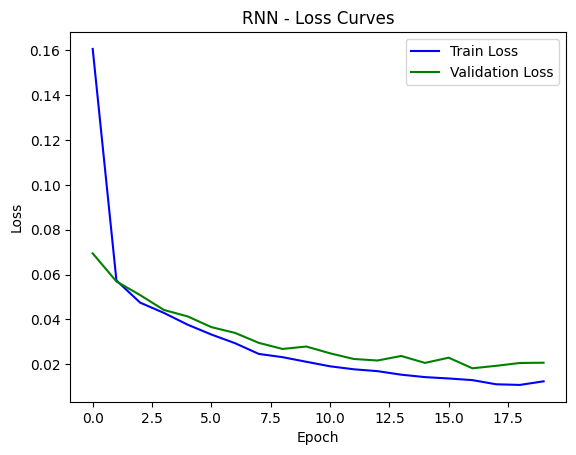

In [24]:
# Plotting loss curves
plt.plot(train_loss_history, color="blue", label="Train Loss")
plt.plot(val_loss_history, color="green", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN - Loss Curves")
plt.legend()
plt.savefig("figures/Task3_RNN_Loss.png", dpi=150)
plt.show()

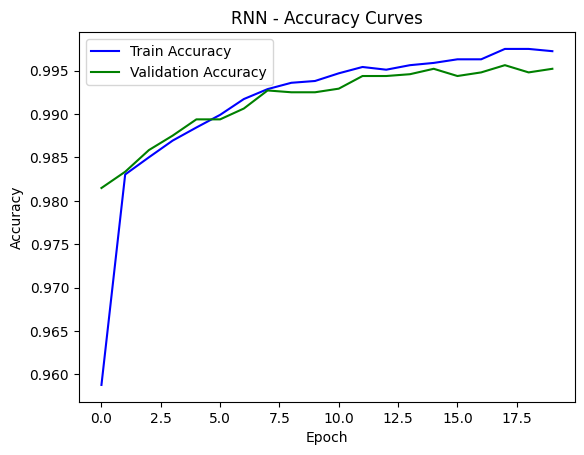

In [25]:
# Plotting accuracy curves
plt.plot(train_acc_history, color="blue", label="Train Accuracy")
plt.plot(val_acc_history, color="green", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN - Accuracy Curves")
plt.legend()
plt.savefig("figures/Task3_RNN_Accuracy.png", dpi=150)
plt.show()

The training plots show that the RNN successfully learned the ECG sequence patterns. Training loss decreased steadily during the epochs, while validation loss remained relatively low and stable. In addition, both training and validation accuracy stayed close to 99%, indicating stable and consistent model performance during training

- **Produce a classification report and confusion matrix on the test set.**

In [26]:
# Final evaluation on test set
rnn.eval()
head.eval()
predict = []
labels = []

with torch.no_grad():
    for X, y in test_loader:
        output, _ = rnn(X)
        last_hidden = output[:, -1, :]
        prediction = head(last_hidden)
        preds = prediction.argmax(1)
        predict.extend(preds.numpy())
        labels.extend(y.numpy())

print("Classification Report:\n")
print(classification_report(labels, predict, target_names=["N", "S", "V"]))

Classification Report:

              precision    recall  f1-score   support

           N       1.00      1.00      1.00      5659
           S       0.84      0.66      0.74        41
           V       0.97      0.95      0.96       308

    accuracy                           0.99      6008
   macro avg       0.94      0.87      0.90      6008
weighted avg       0.99      0.99      0.99      6008



In [27]:
# Accuracy
labels_rnn = labels
predict_rnn = predict

accuracy_rnn = accuracy_score(labels_rnn, predict_rnn)
print("RNN Accuracy:", accuracy_rnn)

RNN Accuracy: 0.9943408788282291


In [28]:
# Macro F1 and recall for S and V
report_rnn = classification_report(
    labels, predict, target_names=["N", "S", "V"], output_dict=True
)

macro_f1_rnn = report_rnn["macro avg"]["f1-score"]
recall_N_rnn = report_rnn["N"]["recall"]
recall_S_rnn = report_rnn["S"]["recall"]
recall_V_rnn = report_rnn["V"]["recall"]

print("Macro F1:", macro_f1_rnn)
print("Recall N:", recall_N_rnn)
print("Recall S:", recall_S_rnn)
print("Recall V:", recall_V_rnn)

Macro F1: 0.9004260102047756
Recall N: 0.9989397420038876
Recall S: 0.6585365853658537
Recall V: 0.9545454545454546


In [29]:
# Confusion matrix
cm_rnn = confusion_matrix(labels, predict)
cm_rnn

array([[5653,    3,    3],
       [   9,   27,    5],
       [  12,    2,  294]])

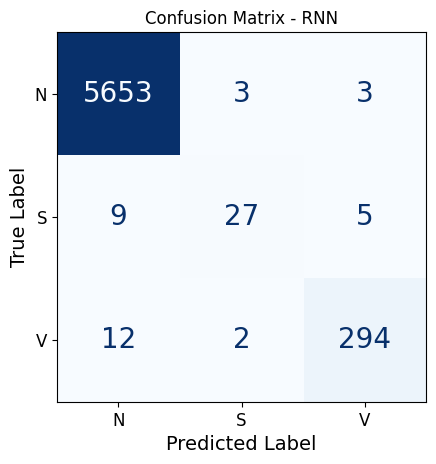

In [30]:
# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rnn, display_labels=["N", "S", "V"])

disp.plot(cmap="Blues", colorbar=False)
plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
for text in disp.ax_.texts:
    text.set_fontsize(20)

plt.title("Confusion Matrix - RNN")
plt.savefig("figures/Task3_ConfusionMatrix_RNN.png", dpi=150)
plt.show()

The model classified the normal class (N) almost perfectly, while the ventricular class (V) also achieved very high performance. In contrast, the supraventricular class (S) obtained lower scores due to the limited number of samples and the imbalance between classes.  

The confusion matrix shows that most ECG beats were classified correctly, with only a few errors mainly affecting the classes with fewer samples.

- **Discuss the vanishing gradient problem in the context of this task. Why does a window of only 10 beats partially mitigate this issue, and why would longer sequences cause problems for a vanilla RNN?**

The vanishing gradient problem occurs in RNNs when gradients become progressively smaller while propagating backwards through time. As a result, the network struggles to learn information from very distant timesteps.  

In this task, using windows of only 10 beats reduces this problem because the sequence is short and the gradients do not need to pass through many temporal steps. Therefore, the RNN can learn local dependencies between ECG beats relatively stably. 

However, with longer sequences, the gradients would weaken, causing the network to forget older information and focus mainly on the most recent beats. This limits the ability of a vanilla RNN to learn long-term dependencies. For this reason, models such as LSTM incorporate memory mechanisms that help preserve relevant information for longer periods of time.

#### **Extension: LSTM (+5 bonus points)**

- **Replace ``torch.nn.RNN`` with ``torch.nn.LSTM`` in your model, keeping all other hyperparameters (hidden size, learning rate, epochs) identical.**

    **Note:** ``nn.LSTM`` returns ``(output, (h_n, c_n))`` instead of ``(output, h_n)`` — that is the only structural change required in the forward pass.

For the LSTM classifier, a single-layer ``torch.nn.LSTM`` was used to process sequences of 8 engineered ECG features per heartbeat. The hidden size is set to 64 to match the vanilla RNN for a fair comparison, and ``batch_first=True`` ensures input tensors are shaped as (batch, sequence, features). The final hidden representation is passed through a fully connected layer that outputs predictions for the three classes (N, S, V). Finally, the model is trained using the Adam optimizer with a learning rate of 0.001 and optimized using cross-entropy loss for multi-class classification.

In [31]:
# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# LSTM classifier
lstm = nn.LSTM(input_size=8, hidden_size=64, num_layers=1, batch_first=True)

head = nn.Linear(64, 3)

optimizer = torch.optim.Adam(
    list(lstm.parameters()) + list(head.parameters()), lr=0.001
)

criterion = nn.CrossEntropyLoss()

The LSTM model is trained for 20 epochs using mini-batch gradient descent with the Adam optimizer. At each epoch, the model is trained on sliding windows of 10 heartbeat feature vectors, and predictions are made using the final hidden representation of the sequence.   

In [32]:
EPOCHS = 20
train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

# Training loop with validation
for epoch in range(EPOCHS):
    lstm.train()
    head.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    # Iterate over training batches
    for x, y in train_loader:
        optimizer.zero_grad()
        # LSTM forward pass
        output, (h_n, c_n) = lstm(x)
        last_hidden = output[:, -1, :]
        pred = head(last_hidden)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_correct += (pred.argmax(1) == y).sum().item()
        train_total += y.size(0)

    lstm.eval()
    head.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for x, y in val_loader:
            output, (h_n, c_n) = lstm(x)
            last_hidden = output[:, -1, :]
            pred = head(last_hidden)
            loss = criterion(pred, y)
            val_loss += loss.item()
            val_correct += (pred.argmax(1) == y).sum().item()
            val_total += y.size(0)

    train_loss_history.append(train_loss / len(train_loader))
    val_loss_history.append(val_loss / len(val_loader))

    train_acc_history.append(train_correct / train_total)
    val_acc_history.append(val_correct / val_total)

    # Print epoch metrics
    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss: {train_loss_history[-1]:.4f}, "
        f"Val Loss: {val_loss_history[-1]:.4f}, "
        f"Train Acc: {train_acc_history[-1]:.4f}, "
        f"Val Acc: {val_acc_history[-1]:.4f}"
    )

Epoch 1: Train Loss: 0.2139, Val Loss: 0.0773, Train Acc: 0.9398, Val Acc: 0.9777
Epoch 2: Train Loss: 0.0567, Val Loss: 0.0536, Train Acc: 0.9835, Val Acc: 0.9838
Epoch 3: Train Loss: 0.0414, Val Loss: 0.0437, Train Acc: 0.9880, Val Acc: 0.9875
Epoch 4: Train Loss: 0.0337, Val Loss: 0.0378, Train Acc: 0.9901, Val Acc: 0.9894
Epoch 5: Train Loss: 0.0282, Val Loss: 0.0352, Train Acc: 0.9921, Val Acc: 0.9892
Epoch 6: Train Loss: 0.0249, Val Loss: 0.0289, Train Acc: 0.9930, Val Acc: 0.9925
Epoch 7: Train Loss: 0.0221, Val Loss: 0.0264, Train Acc: 0.9940, Val Acc: 0.9938
Epoch 8: Train Loss: 0.0195, Val Loss: 0.0253, Train Acc: 0.9945, Val Acc: 0.9940
Epoch 9: Train Loss: 0.0177, Val Loss: 0.0234, Train Acc: 0.9952, Val Acc: 0.9940
Epoch 10: Train Loss: 0.0157, Val Loss: 0.0248, Train Acc: 0.9958, Val Acc: 0.9952
Epoch 11: Train Loss: 0.0145, Val Loss: 0.0222, Train Acc: 0.9962, Val Acc: 0.9948
Epoch 12: Train Loss: 0.0125, Val Loss: 0.0189, Train Acc: 0.9966, Val Acc: 0.9952
Epoch 13: Tra

- **Produce a classification report and plot training curves. Compare macro F1 and perclass recall (especially S and V) against your vanilla RNN. Did performance change? Briefly explain why the LSTM’s gating mechanism might help or make no difference at this sequence length.**

The LSTM model was trained for 20 epochs using batch training. Training and validation loss and accuracy were computed to evaluate the model performance

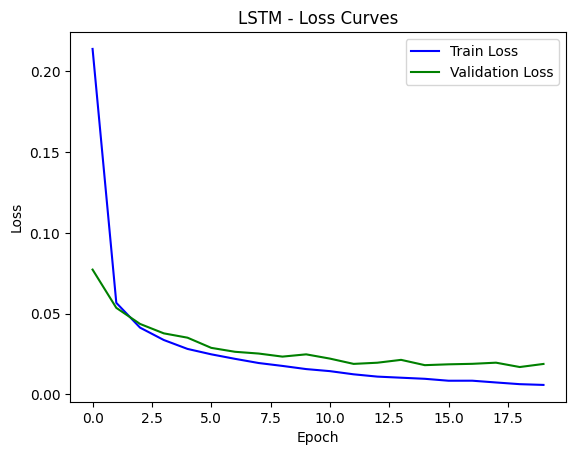

In [33]:
# Plotting loss curves
plt.plot(train_loss_history, label="Train Loss", color="blue")
plt.plot(val_loss_history, label="Validation Loss", color="green")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM - Loss Curves")
plt.legend()
plt.savefig("figures/Task3_LSTM_Loss.png", dpi=150)
plt.show()

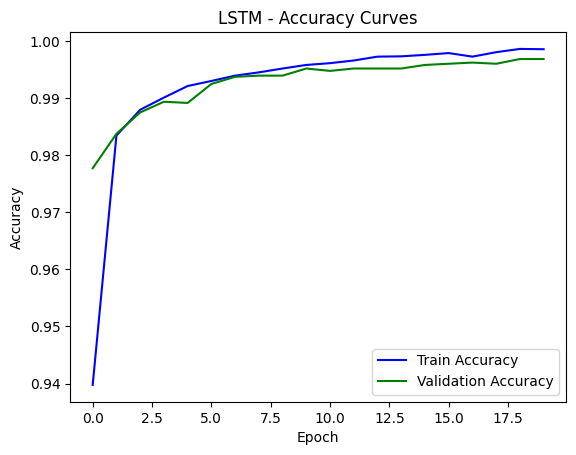

In [34]:
# Plotting accuracy curves
plt.plot(train_acc_history, label="Train Accuracy", color="blue")
plt.plot(val_acc_history, label="Validation Accuracy", color="green")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM - Accuracy Curves")
plt.legend()
plt.savefig("figures/Task3_LSTM_Accuracy.png", dpi=150)
plt.show()

In [35]:
# Final evaluation on test set
lstm.eval()
head.eval()
predict = []
labels = []

with torch.no_grad():
    for X, y in test_loader:
        output, (h_n, c_n) = lstm(X)
        last_hidden = output[:, -1, :]
        prediction = head(last_hidden)

        preds = prediction.argmax(1)

        predict.extend(preds.cpu().numpy())
        labels.extend(y.cpu().numpy())

print("Classification Report:\n")
print(classification_report(labels, predict, target_names=["N", "S", "V"]))

Classification Report:

              precision    recall  f1-score   support

           N       1.00      1.00      1.00      5659
           S       0.90      0.68      0.78        41
           V       0.98      0.96      0.97       308

    accuracy                           0.99      6008
   macro avg       0.96      0.88      0.91      6008
weighted avg       0.99      0.99      0.99      6008



In [36]:
# Accuracy
labels_lstm = labels
predict_lstm = predict

accuracy_lstm = accuracy_score(labels_lstm, predict_lstm)
print("LSTM Accuracy:", accuracy_lstm)

LSTM Accuracy: 0.9948402130492676


In [37]:
# Macro F1 and recall for S and V
report_lstm = classification_report(
    labels, predict, target_names=["N", "S", "V"], output_dict=True
)
macro_f1_lstm = report_lstm["macro avg"]["f1-score"]
recall_N_lstm = report_lstm["N"]["recall"]
recall_S_lstm = report_lstm["S"]["recall"]
recall_V_lstm = report_lstm["V"]["recall"]

print("Macro F1:", macro_f1_lstm)
print("Recall N:", recall_N_lstm)
print("Recall S:", recall_S_lstm)
print("Recall V:", recall_V_lstm)

Macro F1: 0.9142323032749923
Recall N: 0.9991164516699064
Recall S: 0.6829268292682927
Recall V: 0.9577922077922078


In [38]:
# Confusion matrix
cm_lstm = confusion_matrix(labels, predict)
cm_lstm

array([[5654,    1,    4],
       [  10,   28,    3],
       [  11,    2,  295]])

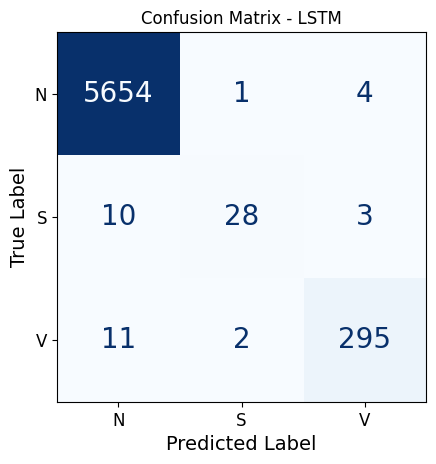

In [39]:
# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lstm, display_labels=["N", "S", "V"])

disp.plot(cmap="Blues", colorbar=False)
plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
for text in disp.ax_.texts:
    text.set_fontsize(20)

plt.title("Confusion Matrix - LSTM")
plt.savefig("figures/Task3_ConfusionMatrix_LSTM.png", dpi=150)
plt.show()

The confusion matrices show that both the RNN and LSTM models achieve strong overall performance, with the majority class (Normal, N) being classified almost perfectly in both cases. The RNN correctly classifies 5653 out of 5659 normal beats, while the LSTM performs slightly better with 5654 correct predictions. Performance on the minority classes is lower but still consistent, reflecting the class imbalance in the dataset.

For supraventricular ectopic beats (S), both models show modest performance, with the LSTM slightly improving correct classification (28 vs 27 true positives) and reducing misclassifications compared to the RNN. Ventricular ectopic beats (V) are classified well by both models, with the LSTM again showing a slight improvement (295 vs 294 correct predictions).

In [40]:
# Comparisoin of RNN and LSTM
print(f"Macro F1 - RNN : {macro_f1_rnn:.4f}")
print(f"Macro F1 - LSTM: {macro_f1_lstm:.4f}")

print(f"\nRecall N - RNN : {recall_N_rnn:.4f}")
print(f"Recall N - LSTM: {recall_N_lstm:.4f}")

print(f"\nRecall S - RNN : {recall_S_rnn:.4f}")
print(f"Recall S - LSTM: {recall_S_lstm:.4f}")

print(f"\nRecall V - RNN : {recall_V_rnn:.4f}")
print(f"Recall V - LSTM: {recall_V_lstm:.4f}")

Macro F1 - RNN : 0.9004
Macro F1 - LSTM: 0.9142

Recall N - RNN : 0.9989
Recall N - LSTM: 0.9991

Recall S - RNN : 0.6585
Recall S - LSTM: 0.6829

Recall V - RNN : 0.9545
Recall V - LSTM: 0.9578


The LSTM model achieved an overall improvement over the vanilla RNN across all key evaluation metrics. Accuracy increased slightly from 0.994 to 0.995, but more importantly, the macro F1-score improved from 0.90 to 0.91, indicating better balanced performance across the three classes.   

The recall of supraventricular ectopic beats (S) increased from 0.66 in the RNN to 0.68 in the LSTM. Performance on ventricular ectopic beats (V) also improved slightly, while performance on normal beats (N) remained almost the same.  

LSTM networks are an extension of RNNs designed to overcome the vanishing gradient problem. LSTMs introduce memory cells and gating mechanisms that control the flow of information through the network. These gates allow the model to selectively retain or discard information over time, enabling it to better capture relevant temporal dependencies in the heartbeat sequences. This is particularly beneficial for detecting rare and irregular rhythm patterns, which depend on subtle variations in the sequence of RR intervals and morphological changes across consecutive beats. 

However, the performance improvement between the RNN and LSTM remained relatively small because the input sequences were limited to only 10 consecutive beats. With such short sequences, the vanishing gradient problem is less severe, allowing the vanilla RNN to capture most of the relevant temporal information effectively. 

<a id='section34'></a>
### **Task 4 - Model Comparison & Evaluation**

- **Produce a summary comparison table with the following columns: Model, Accuracy, Macro F1, Weighted F1.**

In [41]:
# Extract weighted F1 scores
weighted_f1_rnn = report_rnn["weighted avg"]["f1-score"]
weighted_f1_lstm = report_lstm["weighted avg"]["f1-score"]

# Comparison table
comparison_df = pd.DataFrame(
    {
        "Model": ["RNN", "LSTM"],
        "Accuracy": [accuracy_rnn, accuracy_lstm],
        "Macro F1": [macro_f1_rnn, macro_f1_lstm],
        "Weighted F1": [weighted_f1_rnn, weighted_f1_lstm],
    }
)

# Display table
comparison_df.style.format(
    {"Accuracy": "{:.4f}", "Macro F1": "{:.4f}", "Weighted F1": "{:.4f}"}
)

,Model,Accuracy,Macro F1,Weighted F1
0,RNN,0.9943,0.9004,0.9941
1,LSTM,0.9948,0.9142,0.9946


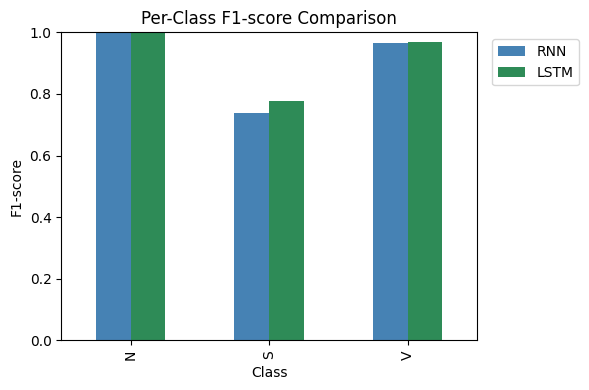

In [42]:
# Per-class F1 comparison bar chart
f1_N_rnn = report_rnn["N"]["f1-score"]
f1_S_rnn = report_rnn["S"]["f1-score"]
f1_V_rnn = report_rnn["V"]["f1-score"]

f1_N_lstm = report_lstm["N"]["f1-score"]
f1_S_lstm = report_lstm["S"]["f1-score"]
f1_V_lstm = report_lstm["V"]["f1-score"]

f1_df = pd.DataFrame(
    {
        "Class": ["N", "S", "V"],
        "RNN": [f1_N_rnn, f1_S_rnn, f1_V_rnn],
        "LSTM": [f1_N_lstm, f1_S_lstm, f1_V_lstm],
    }
)

f1_df.set_index("Class").plot(
    kind="bar", figsize=(6, 4), color=["steelblue", "seagreen"]
)

plt.ylabel("F1-score")
plt.title("Per-Class F1-score Comparison")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

The LSTM outperformed the RNN across all classes, with the most noticeable improvement for class S. This suggests better detection of minority arrhythmia beats.

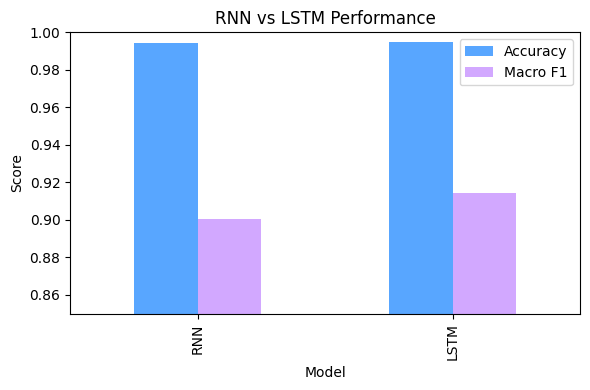

In [43]:
# Overall metric comparison bar chart
metrics_df = pd.DataFrame(
    {
        "Model": ["RNN", "LSTM"],
        "Accuracy": [accuracy_rnn, accuracy_lstm],
        "Macro F1": [macro_f1_rnn, macro_f1_lstm],
    }
)

ax = metrics_df.set_index("Model").plot(
    kind="bar", figsize=(6, 4), color=[ACCENT1, ACCENT4]
)

plt.ylabel("Score")
plt.title("RNN vs LSTM Performance")
plt.ylim(0.85, 1.0)
plt.legend()
plt.tight_layout()
plt.show()

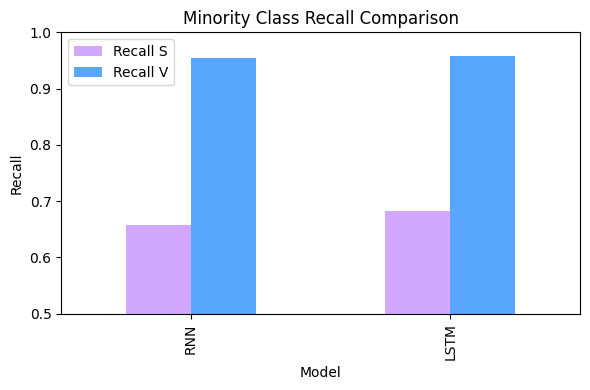

In [44]:
# Minority class recall comparison bar chart
recall_df = pd.DataFrame(
    {
        "Model": ["RNN", "LSTM"],
        "Recall S": [recall_S_rnn, recall_S_lstm],
        "Recall V": [recall_V_rnn, recall_V_lstm],
    }
)

recall_df.set_index("Model").plot(kind="bar", figsize=(6, 4), color=[ACCENT4, ACCENT1])

plt.ylabel("Recall")
plt.title("Minority Class Recall Comparison")
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

To better evaluate the models on the minority classes, recall for S and V beats were compared separately. As shown in the figure, the LSTM achieved higher recall for both classes, with the largest improvement observed for supraventricular ectopic beats (S), where recall increased from 0.66 to 0.78. Recall for ventricular beats (V) also improved slightly. Since missed arrhythmias are clinically more important than small differences in overall accuracy, these results further support the use of the LSTM model for this task.

In [45]:
# Inference time comparison
start = time.time()

rnn.eval()
with torch.no_grad():
    for X, y in test_loader:
        output, _ = rnn(X)
        last_hidden = output[:, -1, :]
        pred = head(last_hidden)

rnn_inference_time = time.time() - start

print(f"RNN inference time: {rnn_inference_time:.4f} s")

start = time.time()
lstm.eval()
with torch.no_grad():
    for X, y in test_loader:
        output, (h_n, c_n) = lstm(X)
        last_hidden = output[:, -1, :]
        pred = head(last_hidden)

lstm_inference_time = time.time() - start

print(f"LSTM inference time: {lstm_inference_time:.4f} s")

RNN inference time: 0.1221 s
LSTM inference time: 0.2095 s


The RNN achieved faster inference (0.09 s) than the LSTM (0.18 s). This is expected because the LSTM contains additional memory cells and gating mechanisms, increasing computational complexity. Despite the higher latency, the LSTM provided better classification performance, particularly for the minority arrhythmia classes, making the trade-off acceptable for this application.

- **Discuss which model you would deploy in a real-time cardiac monitor and why, considering classification performance, latency, interpretability, and the cost of false negatives on ventricular beats.**

Overall, both models achieved excellent performance on the ECG classification task. However, for deployment in a real-time cardiac monitoring system, the LSTM model would be the preferable choice despite its slightly higher computational cost. While the vanilla RNN already achieved very high accuracy, the LSTM consistently produced better overall results, including higher macro F1-score and improved recall for the minority arrhythmia classes, particularly ventricular ectopic beats (V). 

In a clinical environment, false negatives for ventricular beats are especially serious because missed ventricular abnormalities may delay diagnosis and treatment of potentially life-threatening cardiac events. Even a small improvement in ventricular beat detection can  be clinically important. In this case, the LSTM’s gating mechanisms allow it to preserve and selectively update temporal information more effectively than the vanilla RNN. This improves robustness when detecting subtle irregular heartbeat patterns that depend on relationships across multiple consecutive beats. 

Finally, in terms of interpretability, both models are difficult to interpret clinically because their predictions are based on internal hidden representations that cannot be directly explained in medical terms. However, the use of engineered ECG features such as RR intervals, QRS duration, and ST-segment statistics provides some level of interpretability regarding which physiological characteristics influence the predictions.